## Clustering

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans, AgglomerativeClustering, SpectralClustering)
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, rand_score, adjusted_rand_score)
from sklearn.tree import (DecisionTreeClassifier, export_text, plot_tree)
import plotly.express as px
import matplotlib.pyplot as plt
import scipy.stats as sp
from scipy.cluster.hierarchy import (dendrogram, linkage, fcluster, cophenet)
from scipy.spatial.distance import pdist

In [3]:
import os
os.chdir(r"C:\Users\belle\OneDrive\Personal Projects\athlete_profiles\athlete_clustering")

In [4]:
df = pd.read_csv("data/athlete_summary.csv")

In [7]:
scaled_data = StandardScaler().fit_transform(df.drop(['Athlete_ID','Sport'],axis=1).select_dtypes(include=[np.number]))

How many clusters are best fit? We can identify this by using the elbow method.

In [8]:
inertias = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertias.append(kmeans.inertia_)

fig = px.line(x=list(range(1, 11)), 
        y=inertias, 
        labels={'x': 'Number of Clusters', 'y': 'Inertia'}, 
        title='Elbow Method for Optimal k')
fig.show()

Sharp drop off at No. Clusters = 2.

In [9]:
def score_clustering(X, models):
    
    scores = {
            'model': [],
            'silhouette_score': [],
            'davies_bouldin_score': []
            }
    
    for model in models:
        
        model.fit(X)
        if hasattr(model, 'labels_'):
            labels = model.labels_
        else:
            labels = model.predict(X)
        
        scores['silhouette_score'].append(silhouette_score(X, labels))
        scores['davies_bouldin_score'].append(davies_bouldin_score(X, labels))
        scores['model'].append(model.__class__.__name__)
        
    return pd.DataFrame(scores)

In [11]:
models = [
    KMeans(n_clusters=2, random_state=18),
    KMeans(n_clusters=3, random_state=18),
    AgglomerativeClustering(n_clusters=2),
    AgglomerativeClustering(n_clusters=3),
    SpectralClustering(n_clusters=2, random_state=18),
    SpectralClustering(n_clusters=3, random_state=18)
    ]

In [12]:
scores_df = score_clustering(scaled_data, models)
print(scores_df)

                     model  silhouette_score  davies_bouldin_score
0                   KMeans          0.198163              1.750734
1                   KMeans          0.121523              2.216655
2  AgglomerativeClustering          0.158668              1.758073
3  AgglomerativeClustering          0.095735              2.312117
4       SpectralClustering          0.187706              1.770900
5       SpectralClustering          0.141750              1.570700


The silhoette score looks at how well a point is assigned to its cluster by looking at the average distance to other points in the same cluster and the average distance to points in the next nearest cluster. A score closer to 1 indicates good separation and cohesion of clusters, this identifies KMeans with 2 clusters as the best fit.

The Davies Bouldin score is the average similarity of each cluster to the cluster most similar to it. It compare the within cluster distances to the between cluster distances. Lower is better indicating SpectralClustering with 3 clusters to be best performing however all models with 2 clusters also score well.

### Hierarchical Modelling

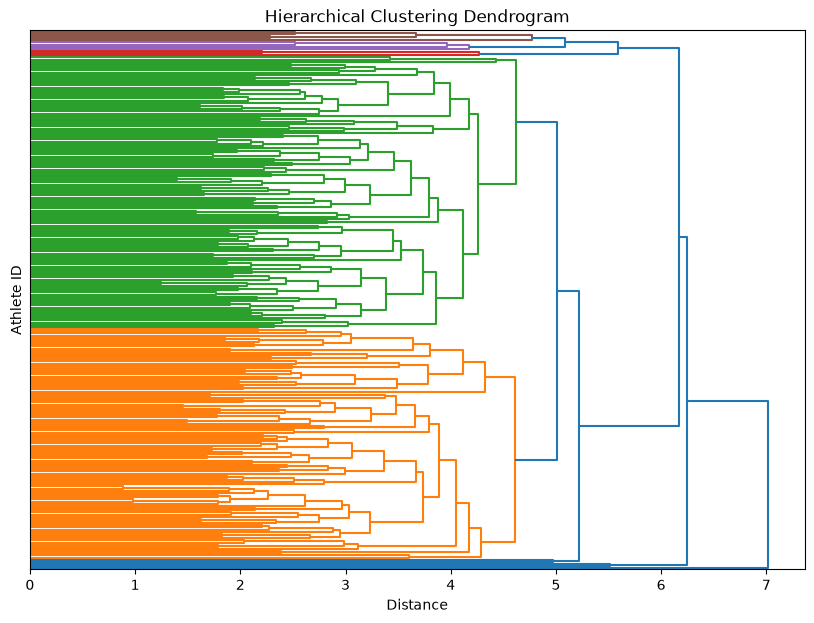

In [32]:
linkage_matrix = linkage(scaled_data, method='average', metric='euclidean')

plt.figure(figsize=(10, 7))
dendrogram(linkage_matrix, 
           #labels=df['Athlete_ID'].values, 
           leaf_rotation=90, 
           leaf_font_size=10,
           orientation='right')
plt.title('Hierarchical Clustering Dendrogram')
plt.ylabel('Athlete ID')
plt.yticks([])
plt.xlabel('Distance')
plt.show()

The cophenetic correlation can tell us how well the dendrogram preserves theoriginal pairwise distances.

In [33]:
Y = pdist(scaled_data)
c, coph_dists = cophenet(linkage_matrix, Y)

print(f"Cophenetic Correlation Coefficient: {c:.4f}")

Cophenetic Correlation Coefficient: 0.6017


A value of 0.6 suggests some distortion. 

### Interpreting KMeans Clusters

In [34]:
labels = KMeans(n_clusters=2, random_state=18).fit_predict(scaled_data)

In [40]:
decision_tree = DecisionTreeClassifier(random_state=18, max_depth=3)

decision_tree.fit(scaled_data, labels)

rules = export_text(decision_tree, 
                    feature_names=list(df.drop(['Athlete_ID','Sport'],axis=1).select_dtypes(include=[np.number]).columns))

print(rules)

|--- Athletics_Performance <= -0.26
|   |--- Tennis_Performance <= 0.14
|   |   |--- Football_Performance <= 0.47
|   |   |   |--- class: 0
|   |   |--- Football_Performance >  0.47
|   |   |   |--- class: 0
|   |--- Tennis_Performance >  0.14
|   |   |--- Resting_Heart_Rate_bpm <= -1.48
|   |   |   |--- class: 0
|   |   |--- Resting_Heart_Rate_bpm >  -1.48
|   |   |   |--- class: 1
|--- Athletics_Performance >  -0.26
|   |--- Basketball_Performance <= -0.26
|   |   |--- Swim_Performance <= -0.05
|   |   |   |--- class: 0
|   |   |--- Swim_Performance >  -0.05
|   |   |   |--- class: 1
|   |--- Basketball_Performance >  -0.26
|   |   |--- Basketball_Performance <= 0.04
|   |   |   |--- class: 1
|   |   |--- Basketball_Performance >  0.04
|   |   |   |--- class: 1



C:\Users\belle\AppData\Local\Temp\ipykernel_18316\401044920.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


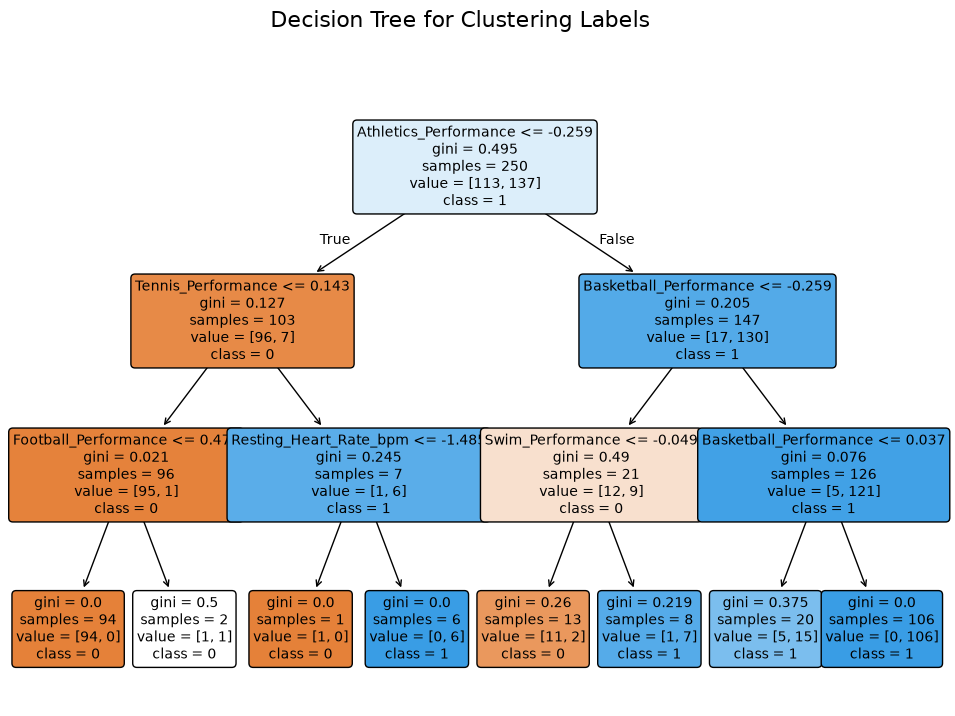

In [41]:
fig = plt.figure(figsize=(12, 8))
plot_tree(decision_tree,
          feature_names=list(df.drop(['Athlete_ID','Sport'],axis=1).select_dtypes(include=[np.number]).columns),
          class_names=[str(i) for i in np.unique(labels)],filled=True, rounded=True, fontsize=10)
fig.suptitle('Decision Tree for Clustering Labels', fontsize=16)
fig.show()

TO-DO: Examine feature distributions over clusters and re-evluate feature space.